In [53]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from analysis_helper import make_contour_plots
import pickle

ROOT = Path("..")
SCRIPTS = ROOT / "scripts"
OUT = SCRIPTS / "qgsp_outputs"

FIT = (
    OUT
    / "fits"
    / "fitno_smear_param_xsec_bias_all_on_qgsp_smear_uncorr_contour_fhc.pkl"
)
RES = (
    OUT
    / "results"
    / "outno_smear_param_xsec_bias_even_split_qgsp_throws_new_param_xsec_fhc.txt"
)

CONT = OUT / "contours"
print(FIT.exists(), RES.exists(), CONT.exists())

True True True


##### 1. Make inflated neutrino datasets
##### 2. Put datasets into histograms with bins matching experiments energy bins
##### 3. Add detector efficiencies and neutrino interaction rates to neutrino histograms (while separating into flavour channels)


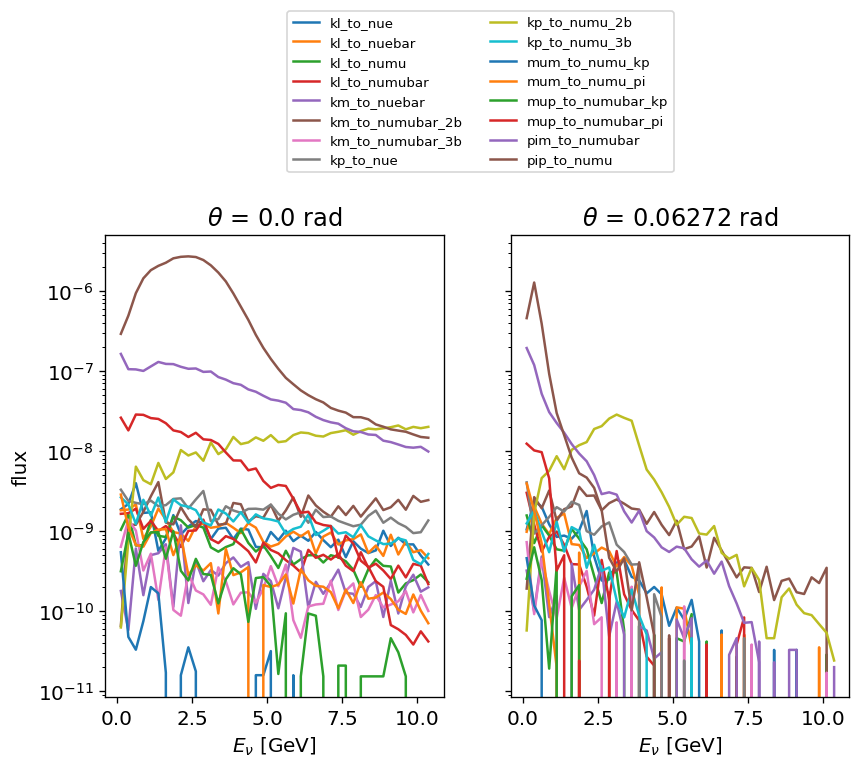

In [ ]:
flux_dir = Path("flux_histos/histtot/10_GeV")
theta = 0.0  # or 0.06272

files = sorted(flux_dir.glob("*offaxis*.txt"))


hists0 = {}
hists06 = {}
for f in files:
    arr = np.loadtxt(f)
    if "06272" in f.stem:
        hists06[f.stem] = arr
    else:
        hists0[f.stem] = arr


fig, ax = plt.subplots(1, 2, figsize=(8, 5), sharey=True)
for name, arr in hists0.items():
    ax[0].plot(arr[:, 0], arr[:, 1], label=name.replace("_offaxis0.0", ""))
for name, arr in hists06.items():
    ax[1].plot(arr[:, 0], arr[:, 1], label=name.replace("_offaxis0.06272", ""))

ax[0].set_xlabel(r"$E_\nu$ [GeV]")
ax[0].set_ylabel(r"flux")
ax[0].set_title("$\\theta$ = 0.0 rad")
ax[0].legend(fontsize=8, ncol=2, bbox_to_anchor=(1.7, 1.5))
ax[0].set_yscale("log")

ax[1].set_xlabel(r"$E_\nu$ [GeV]")
ax[1].set_title("$\\theta$ = 0.06272 rad")
ax[1].set_yscale("log")
plt.show()

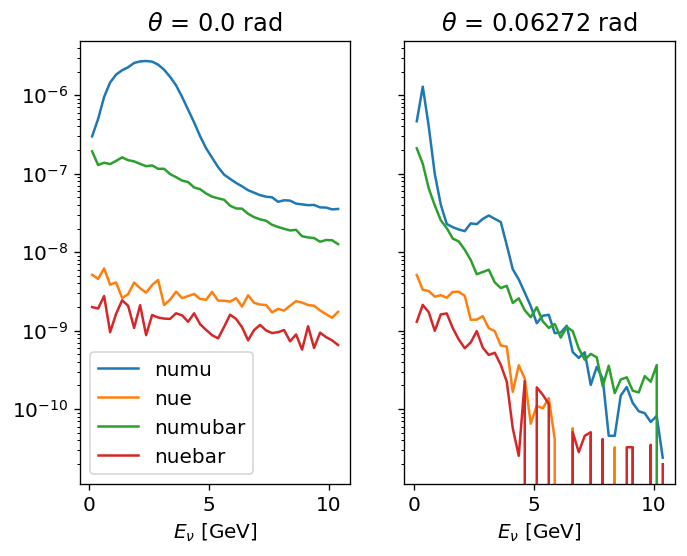

In [51]:
flavours = ["numu", "nue", "numubar", "nuebar"]
flux = {0.0: {}, 0.06272: {}}
theta = [0.0, 0.06272]
Enu = hists0["kl_to_nue_offaxis0.0"][:, 0]

for th in theta:
    for fl in flavours:
        matches = (
            sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}.txt"))
            + sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}_pi.txt"))
            + sorted(flux_dir.glob(f"*_to_{fl}_*offaxis{th}_kp.txt"))
        )
        flav_stacks = [np.loadtxt(f)[:, 1] for f in matches]
        flux[th][fl] = np.sum(flav_stacks, axis=0) if flav_stacks else None

fig, ax = plt.subplots(1, 2, sharey=True)
for fl, y in flux[0.0].items():
    ax[0].plot(Enu, y, label=fl)
for fl, y in flux[0.06272].items():
    ax[1].plot(Enu, y, label=fl)
ax[0].set_yscale("log")
ax[0].legend()
ax[0].set_xlabel(r"$E_\nu$ [GeV]")
ax[0].set_title("$\\theta$ = 0.0 rad")

ax[1].set_yscale("log")
ax[1].set_xlabel(r"$E_\nu$ [GeV]")
ax[1].set_title("$\\theta$ = 0.06272 rad")
plt.show()


In [44]:
flux[0.0]

{'numu': None, 'nue': None, 'numubar': None, 'nuebar': None}

##### 4. Do fit with migrad algorithm

In [61]:
with open(
    "fit_outputs/fits/fitno_smear_param_xsec_bias_all_on_qgsp_test.pkl",
    "rb",
) as f:
    minuit_obj = pickle.load(f)

In [70]:
minuit_obj.fmin

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 1.67e-25                   │              Nfcn = 504              │
│ EDM = 1.51e-21 (Goal: 0.0002)    │           time = 65.3 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘

In [69]:
minuit_obj.params

,Name,Value,Hesse Error,Minos Error-,Minos Error+,Limit-,Limit+,Fixed
0,p_kl,1.00,0.13,,,0,,
1,p_kp,1.000,0.034,,,0,,
2,p_km,1.00,0.04,,,0,,
3,p_pip,1.000,0.033,,,0,,
4,p_pim,1.00,0.07,,,0,,
5,Rqel,1.00,0.04,,,,,
6,Rres,1.00,0.05,,,,,
7,Rdis,1.00,0.05,,,,,
8,Rmec,1.00,0.06,,,,,
9,gammaqel,0.000,0.022,,,,,


In [71]:
minuit_obj.covariance

,p_kl,p_kp,p_km,p_pip,p_pim,Rqel,Rres,Rdis,Rmec,gammaqel,gammares,gammadis,gammamec
p_kl,0.0166,0.0005 (0.123),-0.0008 (-0.165),0.0014 (0.316),-0.005 (-0.549),-0.0008 (-0.132),-0.0004 (-0.060),-0.0025 (-0.366),-0.0002 (-0.033),0.3e-3 (0.122),-0.2e-3 (-0.053),0.11e-3 (0.060),0.001 (0.070)
p_kp,0.0005 (0.123),0.00113,0.0011 (0.853),0.0011 (0.970),0.0011 (0.515),-0.0008 (-0.527),-0.0011 (-0.723),-0.0014 (-0.804),-0.0003 (-0.135),0.2e-3 (0.260),-0.1e-3 (-0.060),-0.03e-3 (-0.056),0.0003 (0.146)
p_km,-0.0008 (-0.165),0.0011 (0.853),0.00143,0.0010 (0.813),0.0019 (0.771),-0.0009 (-0.520),-0.0010 (-0.582),-0.0014 (-0.672),-0.0003 (-0.131),0.1e-3 (0.160),-0.1e-3 (-0.126),-0.14e-3 (-0.265),0.0002 (0.089)
p_pip,0.0014 (0.316),0.0011 (0.970),0.0010 (0.813),0.0011,0.0009 (0.417),-0.0008 (-0.535),-0.0011 (-0.716),-0.0015 (-0.839),-0.0003 (-0.138),0.2e-3 (0.276),-0 (-0.044),-0.03e-3 (-0.054),0.0003 (0.155)
p_pim,-0.005 (-0.549),0.0011 (0.515),0.0019 (0.771),0.0009 (0.417),0.0044,-0.0009 (-0.298),-0.0014 (-0.479),-0.0009 (-0.253),-0.0003 (-0.073),0.1e-3 (0.054),0.2e-3 (0.093),-0.19e-3 (-0.199),0.000 (0.029)
Rqel,-0.0008 (-0.132),-0.0008 (-0.527),-0.0009 (-0.520),-0.0008 (-0.535),-0.0009 (-0.298),0.00202,0.0005 (0.253),0.0006 (0.260),-0.0002 (-0.071),0.3e-3 (0.350),0.4e-3 (0.289),0.08e-3 (0.130),0.0006 (0.198)
Rres,-0.0004 (-0.060),-0.0011 (-0.723),-0.0010 (-0.582),-0.0011 (-0.716),-0.0014 (-0.479),0.0005 (0.253),0.00207,0.0008 (0.325),0.0002 (0.071),-0.3e-3 (-0.281),-0.7e-3 (-0.556),-0.33e-3 (-0.518),-0.0005 (-0.160)
Rdis,-0.0025 (-0.366),-0.0014 (-0.804),-0.0014 (-0.672),-0.0015 (-0.839),-0.0009 (-0.253),0.0006 (0.260),0.0008 (0.325),0.00285,0.0002 (0.061),-0.5e-3 (-0.400),0.5e-3 (0.341),0.30e-3 (0.400),-0.0008 (-0.224)
Rmec,-0.0002 (-0.033),-0.0003 (-0.135),-0.0003 (-0.131),-0.0003 (-0.138),-0.0003 (-0.073),-0.0002 (-0.071),0.0002 (0.071),0.0002 (0.061),0.00325,0.1e-3 (0.101),0.1e-3 (0.068),0.02e-3 (0.025),0.0002 (0.057)
gammaqel,0.3e-3 (0.122),0.2e-3 (0.260),0.1e-3 (0.160),0.2e-3 (0.276),0.1e-3 (0.054),0.3e-3 (0.350),-0.3e-3 (-0.281),-0.5e-3 (-0.400),0.1e-3 (0.101),0.000488,0.1e-3 (0.140),0.02e-3 (0.049),-0.5e-3 (-0.368)


# make visualisation of mesh + rays going through it (or find one from internet)
# explain phasespace package
# show plot of flux contributions from these re-decays
# 

In [3]:
names = [
    "p_kl",
    "p_kp",
    "p_km",
    "p_pip",
    "p_pim",
    "rqel",
    "rres",
    "rdis",
    "rmec",
    "gammaqel",
    "gammares",
    "gammadis",
    "gammamec",
]

print(open(RES).read())

PARAMS = (
    OUT
    / "params"
    / "paramsno_smear_param_xsec_bias_even_split_qgsp_throws_new_param_xsec_fhc.txt"
)
arr = np.loadtxt(PARAMS)
vals, errs = arr[:, 0], arr[:, 1]

for n, v, e in zip(names, vals, errs):
    print(f"{n:10s} = {v:.4f} ± {e:.4f}")

p_kl - 1.12: 1.1200560750706015 ± 0.040088290551312133 
p_kp - 0.83: 0.8300214286151179 ± 0.01403412980079638 
p_km - 1.12: 1.1200216821185507 ± 0.027733121302021435 
p_pip - 0.93: 0.9300282429406996 ± 0.015364288903732648 
p_pim - 1.01: 1.0100017571257567 ± 0.020354144260444906 
rqel - 1.0: 0.9999814741569581 ± 0.023696513535356276 
rres - 1.0: 0.9999482022901783 ± 0.022747704924364686 
rdis - 1.0: 0.9999695894687051 ± 0.02068798075154624 
rmec - 1.0: 1.0000248479205405 ± 0.030398148978046397 
gammaqel - 0.0: 2.05436237711295e-05 ± 0.011283651037850043 
gammares - 0.0: 1.4513797597536711e-05 ± 0.010907223417532527 
gammadis - 0.0: 1.3317718111649367e-05 ± 0.005750610853851945 
gammamec - 0.0: -3.325959945652977e-05 ± 0.03367332734480903 
Final Chi2: 3.4884313309199636e-05 
Calc Chi2: 7.183154539101807e-25 

p_kl       = 1.1201 ± 0.0401
p_kp       = 0.8300 ± 0.0140
p_km       = 1.1200 ± 0.0277
p_pip      = 0.9300 ± 0.0154
p_pim      = 1.0100 ± 0.0204
rqel       = 1.0000 ± 0.0237
rres  

In [4]:
CONT

PosixPath('../scripts/qgsp_outputs/contours')

In [5]:
# pair contour: two columns x,y
c = np.loadtxt(CONT / "p_kl_p_kpsmear_uncorr_contour_fhc.txt")
make_contour_plots((str(CONT) + "/"), "smear_uncorr_contour")


<IPython.core.display.Javascript object>

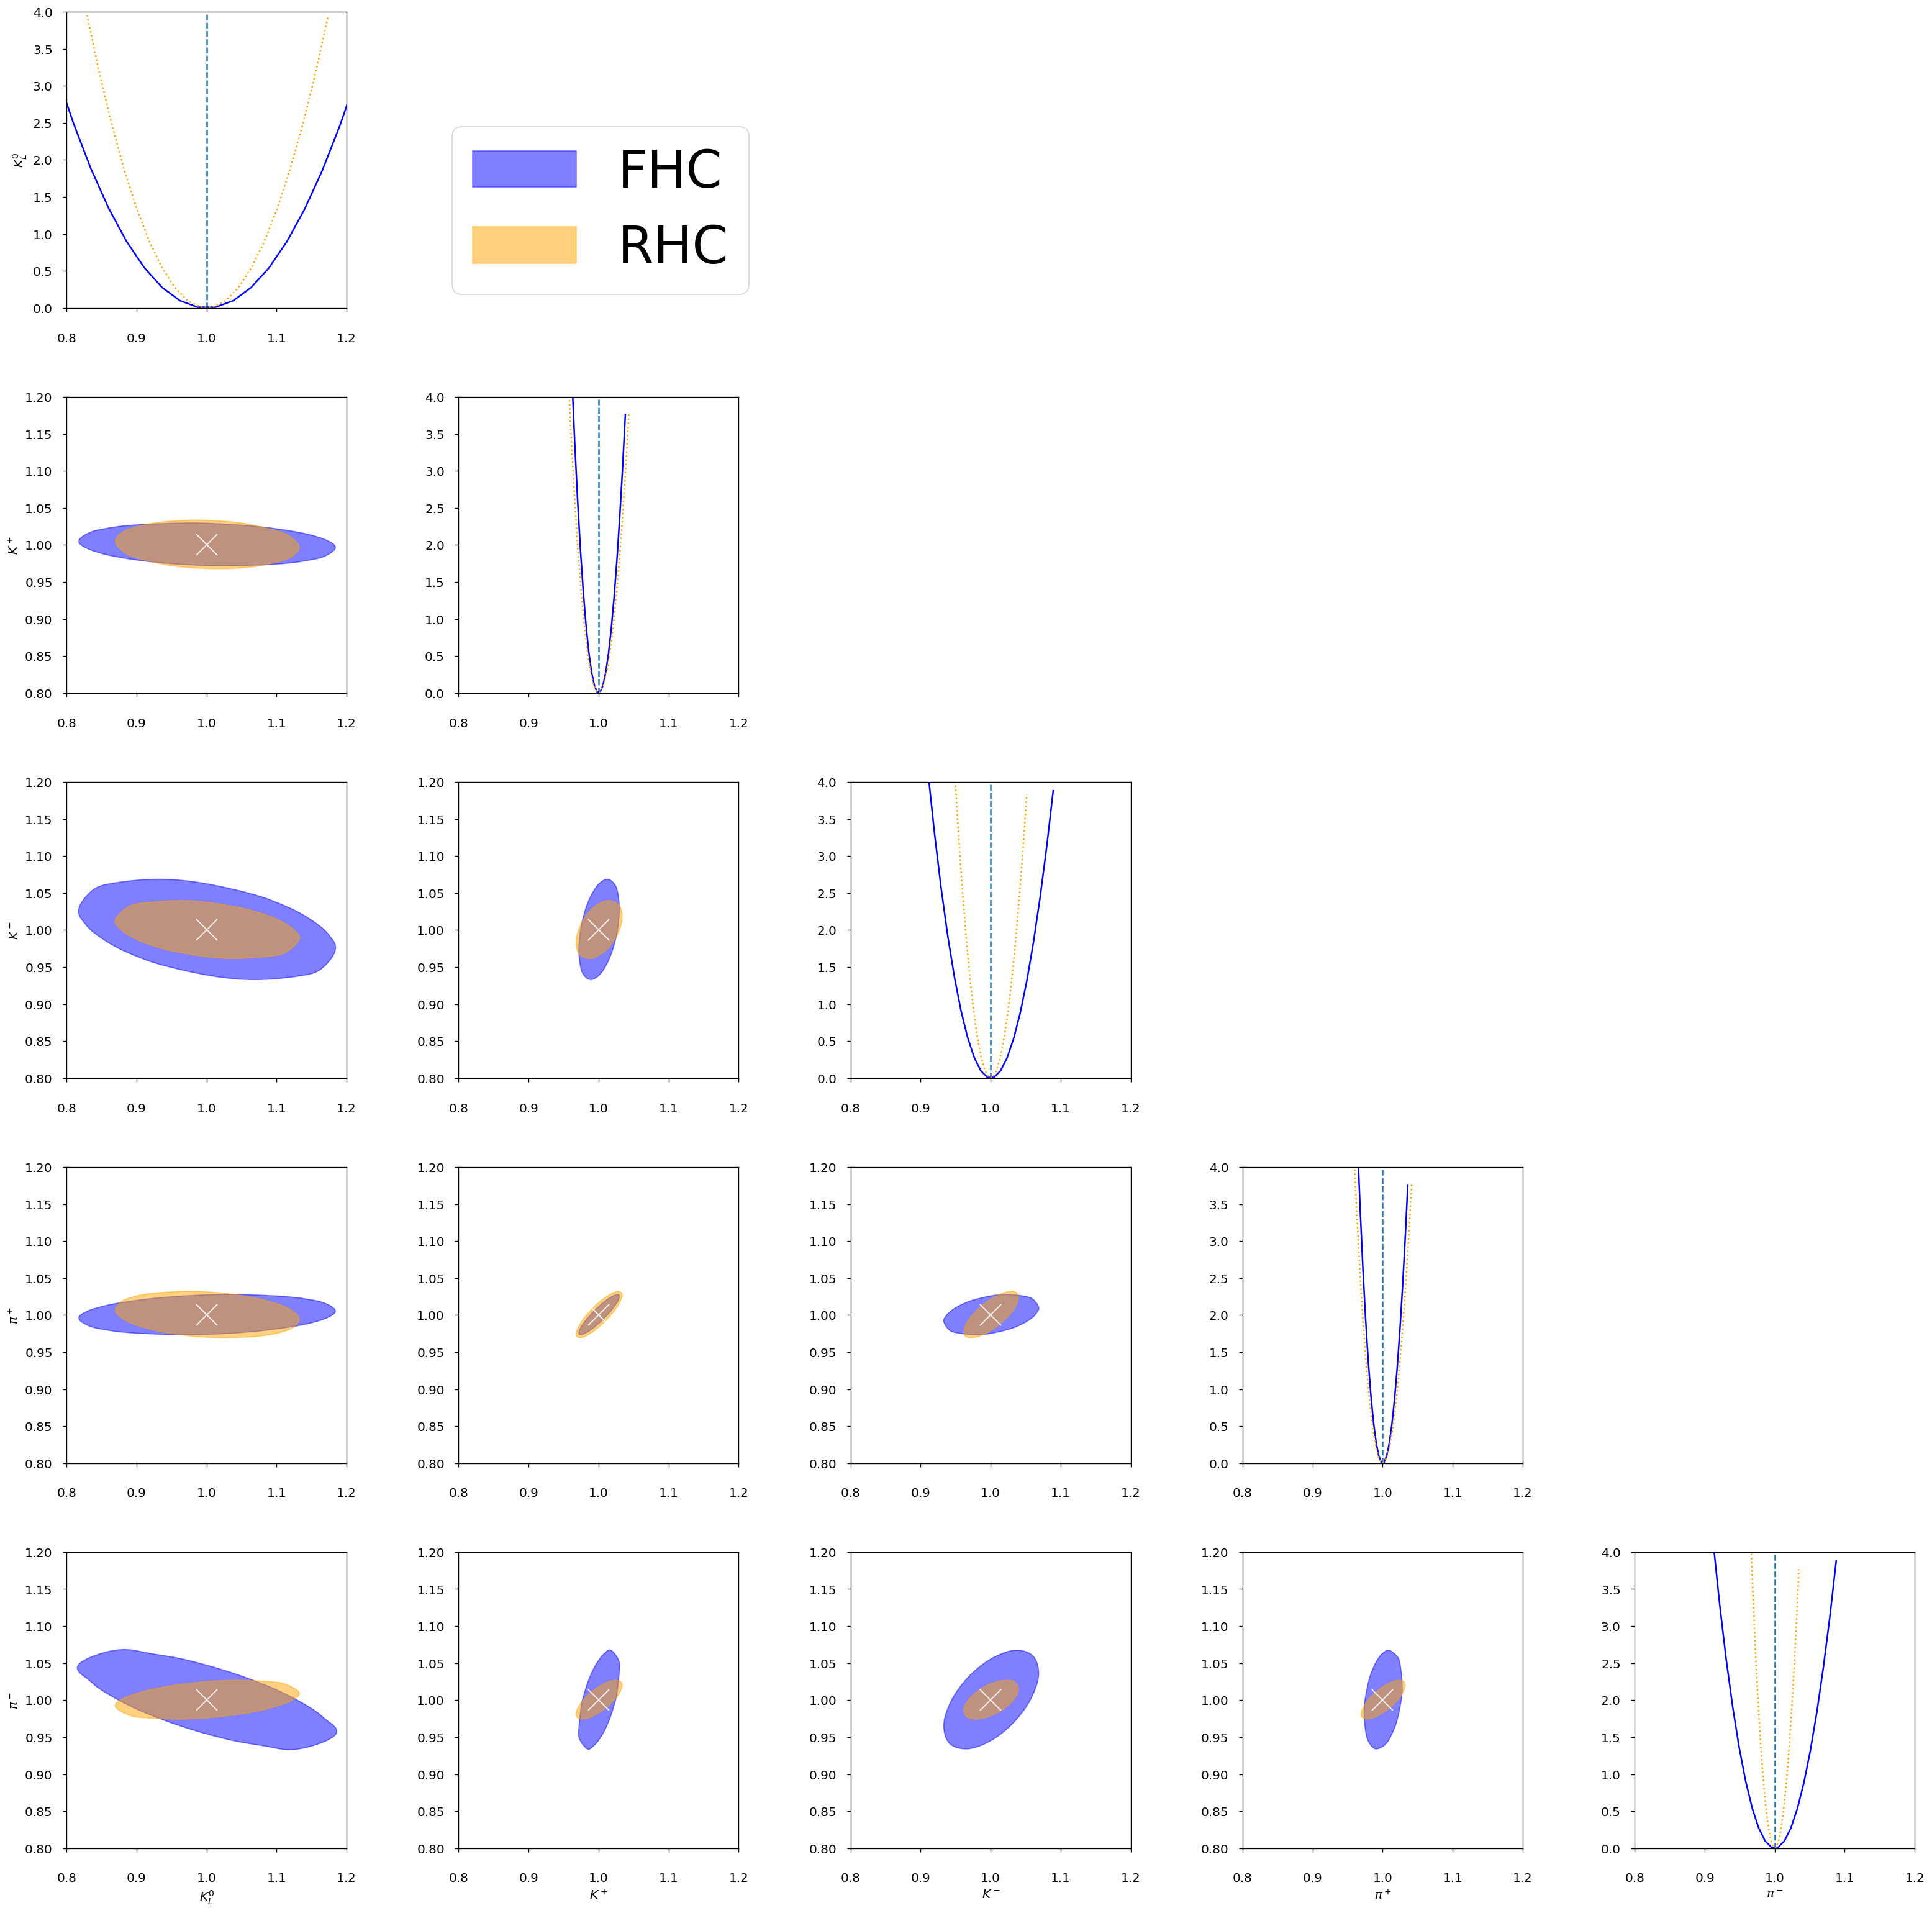

<Figure size 768x576 with 0 Axes>

In [8]:
make_contour_plots(str(CONT) + "/", "smear_uncorr_contour")
plt.show()